# Internet Session Log: Data Analysis and Visualization (EDAV)

**Course:** EDAV (22ADC32N) — Course-End Project  
**Dataset:** `internet_session(1).csv` (uploaded dataset; one row represents one internet session)

## Objective
Explore internet-session activity using NumPy, Pandas, Matplotlib, and Seaborn. The analysis examines session duration, data transfer, user activity, session-break reasons, data quality, and time-based patterns.

> **Dataset alignment note:** This notebook uses the uploaded internet-session CSV. Its columns do not contain Titanic fields such as `Age`, `Survived`, `Pclass`, or `Embarked`, so the analysis and questions are adapted to the fields that actually exist rather than creating unsupported variables.

**Workflow:** Environment setup → dataset inspection → cleaning and feature engineering → NumPy statistics → Pandas grouped analysis → descriptive statistics → visualizations → conclusions.

## 1. Environment Setup

**Concept explanation:** Import the required analysis libraries and set readable display options. The fixed random seed is included for reproducibility if randomized operations are added later.

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
np.random.seed(42)

DATA_FILENAME = "internet_session(1).csv"
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Dataset Inspection

**Concept explanation:** Load the uploaded file, inspect rows and columns, review data types, and identify missing values and duplicates before analysis. The original file uses the misspelled column name `seession_break_reason`; the notebook normalizes it to `session_break_reason` for easier use.

In [2]:
# Prefer the exact filename of the newly uploaded dataset. The alternatives make the
# notebook convenient to run if the CSV is later renamed to internet_session.csv.
data_candidates = [
    Path(DATA_FILENAME),
    Path("data") / DATA_FILENAME,
    Path("internet_session.csv"),
    Path("data") / "internet_session.csv",
]
data_path = next((path.resolve() for path in data_candidates if path.is_file()), None)

if data_path is None:
    raise FileNotFoundError(
        f"Could not find {DATA_FILENAME!r}. Place the uploaded CSV in the same folder "
        "as this notebook, or in a 'data' subfolder."
    )

raw = pd.read_csv(data_path, dtype=str, keep_default_na=False)
raw.columns = [str(column).strip() for column in raw.columns]
raw = raw.replace(r"^\s*$", np.nan, regex=True)

# Standardize the source dataset's misspelled column header.
if "seession_break_reason" in raw.columns and "session_break_reason" not in raw.columns:
    raw = raw.rename(columns={"seession_break_reason": "session_break_reason"})
if "session_break_reason" not in raw.columns:
    raw["session_break_reason"] = np.nan

required_columns = [
    "name", "start_time", "usage_time", "IP", "MAC",
    "upload", "download", "total_transfer"
]
missing_columns = [column for column in required_columns if column not in raw.columns]
if missing_columns:
    raise ValueError(f"The CSV is missing required columns: {missing_columns}")
if raw.empty:
    raise ValueError(f"{data_path.name} contains no data rows.")

print(f"Dataset loaded from: {data_path}")
print(f"Shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
print("Columns:", raw.columns.tolist())
display(raw.head())

Dataset loaded from: /mnt/data/internet_session(1).csv
Shape: 4,712 rows × 9 columns
Columns: ['name', 'start_time', 'usage_time', 'IP', 'MAC', 'upload', 'download', 'total_transfer', 'session_break_reason']


,name,start_time,usage_time,IP,MAC,upload,download,total_transfer,session_break_reason
0,user1,2022-05-10 02:59:32,00:00:36:28,10.55.14.222,48:E7:DA:58:22:E9,15861.76,333168.64,349030.4,Idle-Timeout
1,user1,2022-05-10 18:53:27,00:01:49:56,10.55.2.253,48:E7:DA:58:22:E9,16957.44,212152.32,229109.76,Idle-Timeout
2,user1,2022-05-10 21:20:44,00:01:35:00,10.55.2.253,48:E7:DA:58:22:E9,14080.0,195153.92,209233.92,Idle-Timeout
3,user1,2022-05-11 00:37:42,00:00:26:00,10.55.2.253,48:E7:DA:58:22:E9,5242.88,40806.4,46049.28,Idle-Timeout
4,user1,2022-05-11 02:59:38,00:00:11:52,10.55.2.253,48:E7:DA:58:22:E9,22067.2,10772.48,32839.68,Idle-Timeout


In [3]:
print("Data types as loaded:")
display(raw.dtypes.rename("data_type").to_frame())

print("Missing or blank values per column:")
missing_before_cleaning = raw.isna().sum().sort_values(ascending=False)
display(missing_before_cleaning.rename("missing_values").to_frame())

print(f"Exact duplicate rows: {int(raw.duplicated().sum()):,}")
print("Distinct users:", raw["name"].nunique(dropna=True))
print("Distinct IP addresses:", raw["IP"].nunique(dropna=True))
print("Distinct MAC addresses:", raw["MAC"].nunique(dropna=True))

Data types as loaded:


,data_type
name,object
start_time,object
usage_time,object
IP,object
MAC,object
upload,object
download,object
total_transfer,object
session_break_reason,object


Missing or blank values per column:


,missing_values
session_break_reason,9
name,0
start_time,0
IP,0
usage_time,0
MAC,0
upload,0
download,0
total_transfer,0


Exact duplicate rows: 0
Distinct users: 9
Distinct IP addresses: 1302
Distinct MAC addresses: 33


## 3. Data Cleaning and Feature Engineering (missing-value handling)

**Concept explanation:** Convert timestamps, session durations, and data-transfer measurements into analyzable types. The session duration is stored as `DD:HH:MM:SS`. Transfer values without a suffix are treated as KB-equivalent values; explicit `B`, `KB`, `MB`, `GB`, and `TB` suffixes are normalized to KB. Missing categorical labels are marked `Unknown`, invalid timestamps/durations are excluded, and missing transfer measurements are filled with the median of the available values. Exact duplicate rows are removed, but repeat sessions from the same user are retained because they may be genuine separate sessions.

In [4]:
def parse_usage_time(series: pd.Series) -> pd.Series:
    """Parse DD:HH:MM:SS durations into seconds, returning NaN for invalid values."""
    parts = series.astype("string").str.extract(
        r"^\s*(\d+):(\d{1,2}):(\d{2}):(\d{2})\s*$"
    )
    parts.columns = ["days", "hours", "minutes", "seconds"]
    parts = parts.apply(pd.to_numeric, errors="coerce")
    valid = (
        parts.notna().all(axis=1)
        & parts["hours"].between(0, 23)
        & parts["minutes"].between(0, 59)
        & parts["seconds"].between(0, 59)
    )
    seconds = (
        parts["days"] * 86_400
        + parts["hours"] * 3_600
        + parts["minutes"] * 60
        + parts["seconds"]
    )
    return seconds.where(valid)


TRANSFER_PATTERN = re.compile(r"^\s*([+-]?(?:\d+(?:\.\d*)?|\.\d+))\s*([A-Za-z]*)\s*$")
UNIT_TO_KB = {
    "": 1.0, "B": 1 / 1024, "BYTE": 1 / 1024, "BYTES": 1 / 1024,
    "KB": 1.0, "KIB": 1.0, "MB": 1024.0, "MIB": 1024.0,
    "GB": 1024.0 ** 2, "GIB": 1024.0 ** 2,
    "TB": 1024.0 ** 3, "TIB": 1024.0 ** 3,
}

def parse_transfer_kb(series: pd.Series) -> pd.Series:
    """Convert data-transfer values to KB-equivalent units; unsuffixed values default to KB."""
    values = series.astype("string").str.extract(TRANSFER_PATTERN)
    amount = pd.to_numeric(values[0], errors="coerce")
    unit = values[1].fillna("").str.upper()
    multiplier = unit.map(UNIT_TO_KB)
    return amount * multiplier


# Start from the raw, inspected data and remove exact duplicate records only.
df_work = raw.copy()
exact_duplicates_removed = int(df_work.duplicated().sum())
df_work = df_work.drop_duplicates().copy()
rows_before_validity_filter = len(df_work)

# Parse source fields.
df_work["start_time"] = pd.to_datetime(df_work["start_time"], errors="coerce")
df_work["duration_s"] = parse_usage_time(df_work["usage_time"])
df_work["upload_kb"] = parse_transfer_kb(df_work["upload"])
df_work["download_kb"] = parse_transfer_kb(df_work["download"])
df_work["total_transfer_kb"] = parse_transfer_kb(df_work["total_transfer"])

# A valid timestamp and duration are required for time-based analysis.
invalid_time_mask = df_work["start_time"].isna() | df_work["duration_s"].isna()
invalid_time_rows_removed = int(invalid_time_mask.sum())
df_work = df_work.loc[~invalid_time_mask].copy()

# Normalize missing categorical fields without discarding useful records.
for column in ["name", "IP", "MAC", "session_break_reason"]:
    df_work[column] = df_work[column].fillna("Unknown").astype(str).str.strip()
    df_work.loc[df_work[column].eq(""), column] = "Unknown"

# Missing/unparseable transfer measurements are imputed using the column median.
transfer_columns = ["upload_kb", "download_kb", "total_transfer_kb"]
imputation_values = {}
for column in transfer_columns:
    df_work[column] = pd.to_numeric(df_work[column], errors="coerce")
    if df_work[column].notna().sum() == 0:
        raise ValueError(f"No valid numeric values could be parsed from {column}.")
    median_value = float(df_work[column].median())
    imputation_values[column] = median_value
    df_work[column] = df_work[column].fillna(median_value)

# Convert transfer amounts to MB, derive duration and time features.
df_work["duration_min"] = df_work["duration_s"] / 60.0
df_work["upload_mb"] = df_work["upload_kb"] / 1024.0
df_work["download_mb"] = df_work["download_kb"] / 1024.0
df_work["total_mb"] = df_work["total_transfer_kb"] / 1024.0
df_work["avg_rate_kb_s"] = df_work["total_transfer_kb"] / df_work["duration_s"].replace(0, np.nan)
if df_work["avg_rate_kb_s"].notna().any():
    df_work["avg_rate_kb_s"] = df_work["avg_rate_kb_s"].fillna(df_work["avg_rate_kb_s"].median())
else:
    df_work["avg_rate_kb_s"] = 0.0

df_work["session_date"] = df_work["start_time"].dt.date
df_work["start_hour"] = df_work["start_time"].dt.hour
df_work["weekday"] = df_work["start_time"].dt.day_name()

# The supplied total_transfer column is retained as the primary total. This flag
# highlights rows where upload + download does not closely match that source total.
transfer_difference_kb = (
    df_work["upload_kb"] + df_work["download_kb"] - df_work["total_transfer_kb"]
).abs()
df_work["transfer_components_mismatch"] = transfer_difference_kb > np.maximum(
    1.0, df_work["total_transfer_kb"].abs() * 0.01
)

df_clean = df_work.reset_index(drop=True)
print("Cleaning complete.")
print(f"Exact duplicate rows removed: {exact_duplicates_removed:,}")
print(f"Rows removed for invalid start time/duration: {invalid_time_rows_removed:,}")
print(f"Rows retained for analysis: {len(df_clean):,}")
print(f"Rows where upload + download differs from total_transfer by >1% or 1 KB: {int(df_clean['transfer_components_mismatch'].sum()):,}")

Cleaning complete.
Exact duplicate rows removed: 0
Rows removed for invalid start time/duration: 0
Rows retained for analysis: 4,712
Rows where upload + download differs from total_transfer by >1% or 1 KB: 0


### 3.1 Missing-Value and Data-Quality Checks

**Concept explanation:** Verify the effects of cleaning and report which numeric medians were used for imputation. The source's `total_transfer` measurement is preserved as the primary total; rows with noticeably inconsistent upload/download components are flagged rather than silently overwritten.

In [5]:
print("Median fallback values for transfer fields (KB-equivalent; applied only if needed):")
display(pd.Series(imputation_values, name="median_imputation_value").to_frame())

print("Missing values after cleaning:")
post_clean_missing = df_clean.isna().sum().sort_values(ascending=False)
display(post_clean_missing.rename("missing_values").to_frame())
print("Total remaining missing cells:", int(df_clean.isna().sum().sum()))

print("Numeric metric summary:")
display(
    df_clean[["duration_min", "upload_mb", "download_mb", "total_mb", "avg_rate_kb_s"]]
    .describe()
    .round(3)
)

if int(df_clean.isna().sum().sum()) == 0:
    print("Validation passed: the cleaned analysis dataset contains no missing cells.")
else:
    print("Note: some derived or source fields still contain missing values; inspect the table above.")

Median fallback values for transfer fields (KB-equivalent; applied only if needed):


,median_imputation_value
upload_kb,"15,329.28"
download_kb,"178,268.16"
total_transfer_kb,"202,931.20"


Missing values after cleaning:


,missing_values
name,0
start_time,0
usage_time,0
IP,0
MAC,0
upload,0
download,0
total_transfer,0
session_break_reason,0
duration_s,0


Total remaining missing cells: 0
Numeric metric summary:


,duration_min,upload_mb,download_mb,total_mb,avg_rate_kb_s
count,"4,712.00","4,712.00","4,712.00","4,712.00","4,712.00"
mean,130.40,33.03,387.27,420.29,71.12
std,153.60,92.70,942.37,971.94,117.33
min,0.02,0.00,0.00,0.00,0.10
25%,31.82,5.94,50.80,60.42,20.81
50%,79.73,14.97,174.09,198.18,42.48
75%,169.40,33.20,448.72,487.98,79.33
max,"1,461.12","2,775.04","27,248.64","27,883.52","2,428.50"


Validation passed: the cleaned analysis dataset contains no missing cells.


## 4. Q1 — NumPy Statistics for Session Duration and Data Transfer

**Concept explanation:** Use NumPy array operations to calculate the average, minimum, and maximum session duration and total transfer volume for each session-break reason. This adapts the PDF's NumPy statistics task to metrics available in this dataset. The `Unknown` category keeps sessions with a missing break reason visible in the analysis.

In [6]:
numpy_stats = []
for reason, group in df_clean.groupby("session_break_reason", dropna=False):
    durations = group["duration_min"].dropna().to_numpy(dtype=float)
    transfers = group["total_mb"].dropna().to_numpy(dtype=float)
    if durations.size == 0 or transfers.size == 0:
        continue
    numpy_stats.append({
        "Session-break reason": reason,
        "Sessions": int(len(group)),
        "Mean duration (min)": float(np.mean(durations)),
        "Minimum duration (min)": float(np.min(durations)),
        "Maximum duration (min)": float(np.max(durations)),
        "Mean total transfer (MB)": float(np.mean(transfers)),
        "Minimum total transfer (MB)": float(np.min(transfers)),
        "Maximum total transfer (MB)": float(np.max(transfers)),
    })

numpy_stats_df = pd.DataFrame(numpy_stats).sort_values("Sessions", ascending=False)
display(numpy_stats_df.round(3))

,Session-break reason,Sessions,Mean duration (min),Minimum duration (min),Maximum duration (min),Mean total transfer (MB),Minimum total transfer (MB),Maximum total transfer (MB)
0,Idle-Timeout,4350,129.01,0.02,"1,461.12",424.32,0.00,"27,883.52"
1,Lost-Carrier,162,163.83,0.48,948.60,340.00,0.01,"3,092.48"
2,Lost-Service,124,129.67,0.63,"1,003.13",459.20,0.02,"2,836.48"
5,User-Request,65,141.47,9.00,644.98,288.67,0.39,"1,484.80"
4,Unknown,9,141.02,14.43,251.47,388.20,9.32,"1,218.56"
3,NAS-Reboot,2,68.99,32.98,105.00,167.81,104.08,231.53


## 5. Q2 — Pandas Analysis by User and Session-Break Reason

**Concept explanation:** Use `groupby` and aggregations to compare activity across users and session-break reasons. Session counts, total transferred data, median duration, and typical per-session transfer help describe network usage without assuming one variable causes another.

In [7]:
by_user = (
    df_clean.groupby("name", as_index=False)
    .agg(
        sessions=("name", "size"),
        unique_ips=("IP", "nunique"),
        total_data_mb=("total_mb", "sum"),
        median_session_min=("duration_min", "median"),
        mean_session_mb=("total_mb", "mean"),
    )
    .sort_values("total_data_mb", ascending=False)
)
by_reason = (
    df_clean.groupby("session_break_reason", as_index=False)
    .agg(
        sessions=("name", "size"),
        total_data_mb=("total_mb", "sum"),
        median_session_min=("duration_min", "median"),
        mean_session_mb=("total_mb", "mean"),
    )
)
by_reason["session_share_pct"] = by_reason["sessions"] / len(df_clean) * 100
by_reason = by_reason.sort_values("sessions", ascending=False)

print("User activity summary:")
display(by_user.round(2))
print("Session-break reason summary:")
display(by_reason.round(2))

User activity summary:


,name,sessions,unique_ips,total_data_mb,median_session_min,mean_session_mb
8,user9,572,289,"344,292.70",85.71,601.91
3,user4,727,211,"313,353.25",94.22,431.02
1,user2,457,193,"269,042.49",61.62,588.71
6,user7,528,132,"246,209.83",90.58,466.31
0,user1,674,130,"196,276.09",65.01,291.21
5,user6,674,130,"196,276.09",65.01,291.21
2,user3,519,239,"188,706.19",97.98,363.60
4,user5,336,188,"138,197.20",58.42,411.30
7,user8,225,117,"88,040.54",146.65,391.29


Session-break reason summary:


,session_break_reason,sessions,total_data_mb,median_session_min,mean_session_mb,session_share_pct
0,Idle-Timeout,4350,"1,845,780.85",78.97,424.32,92.32
1,Lost-Carrier,162,"55,079.19",89.57,340.00,3.44
2,Lost-Service,124,"56,941.46",71.29,459.21,2.63
5,User-Request,65,"18,763.47",90.03,288.67,1.38
4,Unknown,9,"3,493.80",150.72,388.20,0.19
3,NAS-Reboot,2,335.61,68.99,167.80,0.04


## 6. Q4 — Descriptive Statistics by Weekday and Session-Break Reason

**Concept explanation:** Group sessions by the weekday on which they started and by session-break reason. Counts and duration/transfer summaries show whether the observed mix of sessions differs across days. A second table summarizes session activity by start date.

In [8]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_reason_stats = (
    df_clean.groupby(["weekday", "session_break_reason"], as_index=False)
    .agg(
        session_count=("name", "size"),
        mean_duration_min=("duration_min", "mean"),
        median_duration_min=("duration_min", "median"),
        mean_transfer_mb=("total_mb", "mean"),
        median_transfer_mb=("total_mb", "median"),
    )
)
weekday_reason_stats["weekday"] = pd.Categorical(
    weekday_reason_stats["weekday"], categories=weekday_order, ordered=True
)
weekday_reason_stats = weekday_reason_stats.sort_values(["weekday", "session_break_reason"])
print("Grouped descriptive statistics (weekday × session-break reason):")
display(weekday_reason_stats.round(2))

daily_summary = (
    df_clean.groupby("session_date", as_index=False)
    .agg(
        sessions=("name", "size"),
        unique_users=("name", "nunique"),
        total_transfer_mb=("total_mb", "sum"),
        median_duration_min=("duration_min", "median"),
    )
    .sort_values("session_date")
)
print("Daily summary (first and last 5 dates):")
display(pd.concat([daily_summary.head(5), daily_summary.tail(5)]).drop_duplicates().round(2))

Grouped descriptive statistics (weekday × session-break reason):


,weekday,session_break_reason,session_count,mean_duration_min,median_duration_min,mean_transfer_mb,median_transfer_mb
5,Monday,Idle-Timeout,580,112.66,60.07,431.49,143.15
6,Monday,Lost-Carrier,23,177.79,103.53,456.16,213.05
7,Monday,Lost-Service,27,103.32,27.98,365.63,100.40
8,Monday,User-Request,6,187.48,169.47,180.48,97.62
22,Tuesday,Idle-Timeout,676,116.22,74.98,367.12,187.15
23,Tuesday,Lost-Carrier,33,120.29,58.97,228.55,61.78
24,Tuesday,Lost-Service,12,131.44,102.04,383.13,218.24
25,Tuesday,User-Request,19,92.85,36.03,282.11,170.29
26,Wednesday,Idle-Timeout,605,129.97,81.97,380.95,206.69
27,Wednesday,Lost-Carrier,25,203.49,82.68,454.24,103.18


Daily summary (first and last 5 dates):


,session_date,sessions,unique_users,total_transfer_mb,median_duration_min
0,2022-05-09,1,1,107.27,85.02
1,2022-05-10,30,8,"4,441.43",34.39
2,2022-05-11,25,8,"10,035.54",51.05
3,2022-05-12,25,7,"8,305.85",69.60
4,2022-05-13,24,7,"6,962.65",46.32
149,2022-11-01,34,8,"12,433.33",84.99
150,2022-11-02,38,8,"17,194.54",106.84
151,2022-11-03,29,8,"9,863.31",74.65
152,2022-11-04,29,8,"12,021.94",108.15
153,2022-11-05,30,8,"10,936.17",84.78


## 7. Q5 — Bar Plot and Heatmap Visualizations

**Concept explanation:** Use a bar plot to compare session counts by break reason, a heatmap to compare user activity across break reasons, and a weekday-by-hour heatmap to reveal time-of-week patterns. Axes, titles, and color bars are labeled for interpretation.

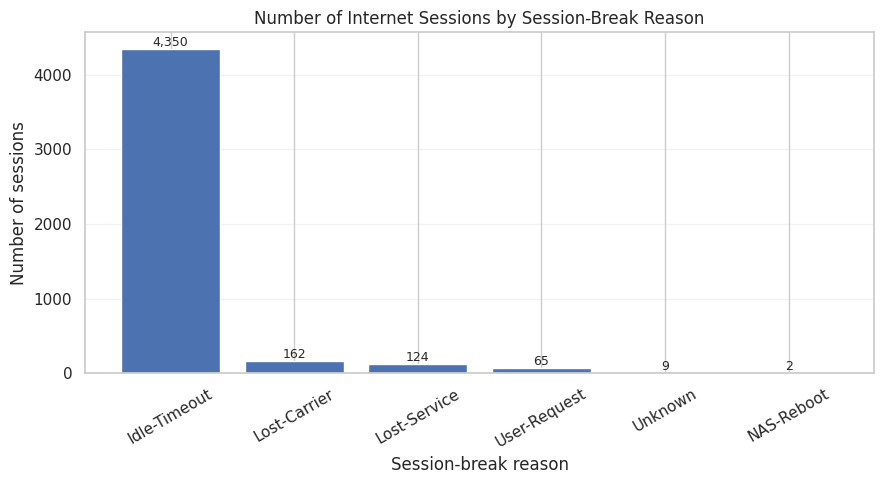

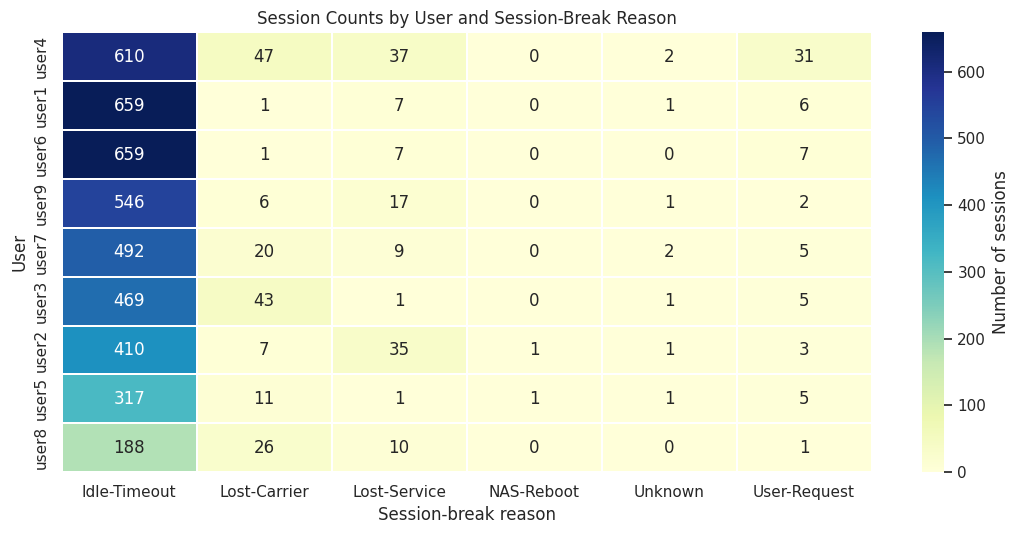

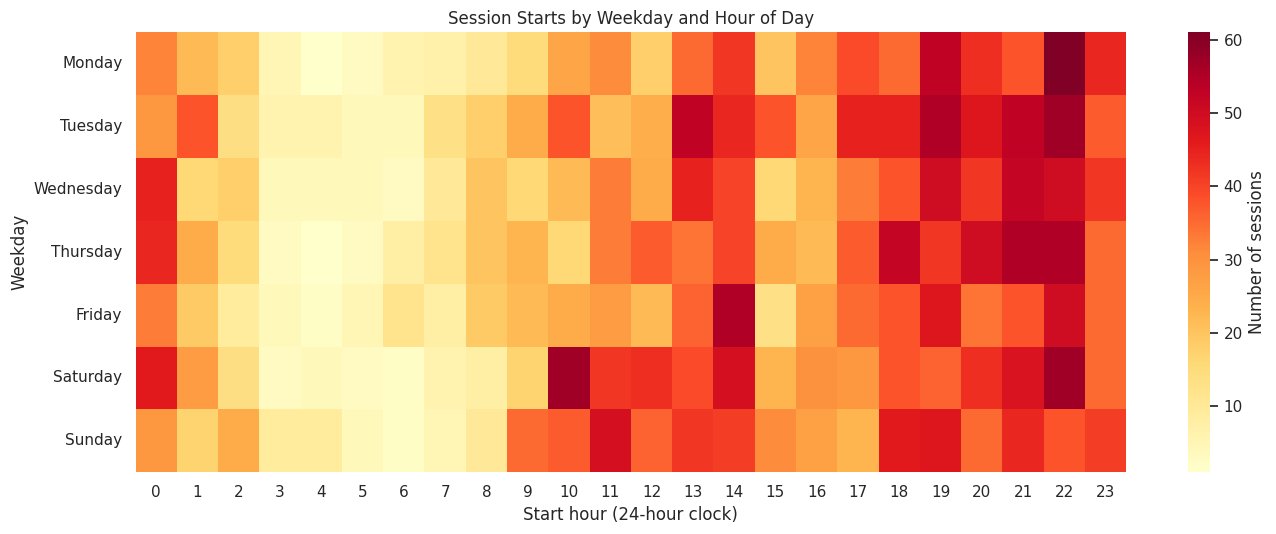

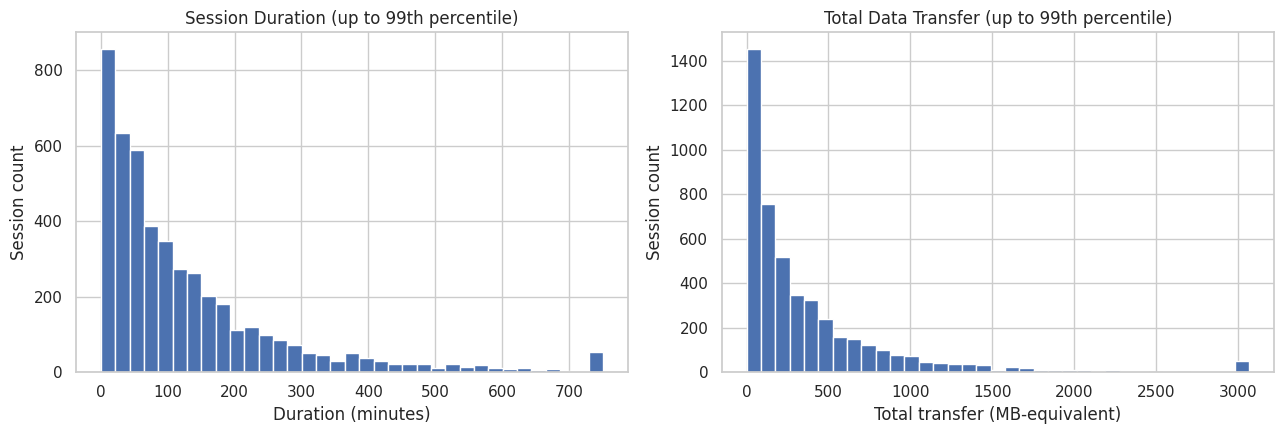

In [9]:
# 7.1 Bar plot: session counts by session-break reason.
reason_counts = df_clean["session_break_reason"].value_counts().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(reason_counts.index.astype(str), reason_counts.values)
ax.set_title("Number of Internet Sessions by Session-Break Reason")
ax.set_xlabel("Session-break reason")
ax.set_ylabel("Number of sessions")
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.25)
for position, value in enumerate(reason_counts.values):
    ax.text(position, value, f"{value:,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

# 7.2 Heatmap: session counts by user and session-break reason.
user_reason_counts = pd.crosstab(df_clean["name"], df_clean["session_break_reason"])
user_reason_counts = user_reason_counts.loc[user_reason_counts.sum(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.heatmap(user_reason_counts, annot=True, fmt="d", cmap="YlGnBu", linewidths=0.3, ax=ax,
            cbar_kws={"label": "Number of sessions"})
ax.set_title("Session Counts by User and Session-Break Reason")
ax.set_xlabel("Session-break reason")
ax.set_ylabel("User")
plt.tight_layout()
plt.show()

# 7.3 Heatmap: session starts by weekday and hour.
weekday_hour_counts = pd.crosstab(df_clean["weekday"], df_clean["start_hour"])
weekday_hour_counts = weekday_hour_counts.reindex(weekday_order, fill_value=0)
weekday_hour_counts = weekday_hour_counts.reindex(columns=range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(14, 5.5))
sns.heatmap(weekday_hour_counts, cmap="YlOrRd", ax=ax,
            cbar_kws={"label": "Number of sessions"})
ax.set_title("Session Starts by Weekday and Hour of Day")
ax.set_xlabel("Start hour (24-hour clock)")
ax.set_ylabel("Weekday")
plt.tight_layout()
plt.show()

# 7.4 Distribution plot: duration and total transfer are typically right-skewed.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
duration_cap = df_clean["duration_min"].quantile(0.99)
transfer_cap = df_clean["total_mb"].quantile(0.99)
axes[0].hist(df_clean["duration_min"].clip(upper=duration_cap), bins=35, edgecolor="white")
axes[0].set_title("Session Duration (up to 99th percentile)")
axes[0].set_xlabel("Duration (minutes)")
axes[0].set_ylabel("Session count")
axes[1].hist(df_clean["total_mb"].clip(upper=transfer_cap), bins=35, edgecolor="white")
axes[1].set_title("Total Data Transfer (up to 99th percentile)")
axes[1].set_xlabel("Total transfer (MB-equivalent)")
axes[1].set_ylabel("Session count")
plt.tight_layout()
plt.show()

## 8. Final Conclusion and Insights

**Concept explanation:** Summarize the patterns calculated above. The conclusions are generated from the data at runtime so they update if the CSV changes. These are descriptive findings and should not be interpreted as evidence of cause and effect.

In [10]:
overall_sessions = len(df_clean)
start_min = df_clean["start_time"].min()
start_max = df_clean["start_time"].max()
most_common_reason = df_clean["session_break_reason"].value_counts().idxmax()
most_common_reason_count = int(df_clean["session_break_reason"].value_counts().max())
top_user_sessions = by_user.sort_values("sessions", ascending=False).iloc[0]
top_user_volume = by_user.iloc[0]
busiest_weekday = df_clean["weekday"].value_counts().idxmax()
busiest_hour = int(df_clean["start_hour"].value_counts().idxmax())
median_duration = float(df_clean["duration_min"].median())
median_transfer = float(df_clean["total_mb"].median())
all_upload_mb = float(df_clean["upload_mb"].sum())
all_download_mb = float(df_clean["download_mb"].sum())

print(f"Records analyzed: {overall_sessions:,}")
print(f"Session start date range: {start_min:%Y-%m-%d} to {start_max:%Y-%m-%d}")
print(f"Most frequent session-break reason: {most_common_reason} ({most_common_reason_count:,} sessions, {most_common_reason_count / overall_sessions:.1%})")
print(f"User with the most sessions: {top_user_sessions['name']} ({int(top_user_sessions['sessions']):,} sessions)")
print(f"User with the highest total recorded transfer: {top_user_volume['name']} ({top_user_volume['total_data_mb']:,.2f} MB-equivalent)")
print(f"Median session duration: {median_duration:,.2f} minutes")
print(f"Median total transfer per session: {median_transfer:,.2f} MB-equivalent")
print(f"Weekday with the most session starts: {busiest_weekday}")
print(f"Hour with the most session starts: {busiest_hour:02d}:00–{(busiest_hour + 1) % 24:02d}:00")
print(f"Recorded upload total: {all_upload_mb:,.2f} MB-equivalent")
print(f"Recorded download total: {all_download_mb:,.2f} MB-equivalent")

print("\nInterpretation:")
print(f"- {most_common_reason} is the leading recorded session-break reason in this dataset.")
print(f"- Session activity is not evenly distributed across users; {top_user_sessions['name']} has the largest session count.")
print(f"- The weekday/hour summaries and heatmaps show when session starts are more concentrated.")
notable_component_mismatches = int(df_clean["transfer_components_mismatch"].sum())
if notable_component_mismatches:
    print(f"- {notable_component_mismatches:,} rows exceed the chosen tolerance when upload + download is compared with total_transfer; the supplied total_transfer value is retained for total-volume analysis.")
else:
    print("- No rows exceed the chosen tolerance (greater of 1 KB or 1% of total_transfer) when upload + download is compared with total_transfer.")
print("- Transfer units are treated as KB-equivalent when no suffix is provided. Interpret MB values under that documented assumption.")

Records analyzed: 4,712
Session start date range: 2022-05-09 to 2022-11-05
Most frequent session-break reason: Idle-Timeout (4,350 sessions, 92.3%)
User with the most sessions: user4 (727 sessions)
User with the highest total recorded transfer: user9 (344,292.70 MB-equivalent)
Median session duration: 79.73 minutes
Median total transfer per session: 198.18 MB-equivalent
Weekday with the most session starts: Tuesday
Hour with the most session starts: 22:00–23:00
Recorded upload total: 155,625.30 MB-equivalent
Recorded download total: 1,824,836.70 MB-equivalent

Interpretation:
- Idle-Timeout is the leading recorded session-break reason in this dataset.
- Session activity is not evenly distributed across users; user4 has the largest session count.
- The weekday/hour summaries and heatmaps show when session starts are more concentrated.
- No rows exceed the chosen tolerance (greater of 1 KB or 1% of total_transfer) when upload + download is compared with total_transfer.
- Transfer units a

## Reproducibility Notes

- Keep `internet_session(1).csv` in the same folder as this notebook (or in a `data/` subfolder) before running **Run All**.
- The loader prioritizes the uploaded filename `internet_session(1).csv`; it also accepts `internet_session.csv` if the file is renamed.
- The source misspelling `seession_break_reason` is normalized in memory; the CSV itself is not changed.
- No Titanic passenger-survival conclusions are made because this dataset contains internet-session logs rather than passenger records.